# Análisis de empleados: recolección, limpieza y estadística

**Proyecto:** dashboards de RR.HH. y administración en Power BI
**Dataset:** `Empleados.csv` (Kaggle) · **Autor y enlace:** *[completar con el autor, el enlace y la licencia de Kaggle]*

**Contenido**
1. Recolección
2. Exploración inicial
3. Limpieza y columnas nuevas
4. Estadística descriptiva (media, mediana, moda y desviación estándar)
5. Visualizaciones
6. ¿Importan las filas repetidas?
7. Conclusiones
8. Exportación del dataset limpio

> Este notebook se ejecuta desde la carpeta `notebooks/`. La limpieza vive en `scripts/limpiar_empleados.py` y aquí se explica y se verifica.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sys.path.insert(0, "../scripts")
from limpiar_empleados import limpiar

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RAW = Path("../data/raw/Empleados.csv")
CLEAN = Path("../data/clean/empleados_limpio.csv")

## 1. Recolección

El archivo se descargó de Kaggle y se guardó **sin modificar** en `data/raw/`. Cada fila es un empleado; no hay identificador.

In [2]:
raw = pd.read_csv(RAW)
print("Filas y columnas:", raw.shape)
print("Total de datos (filas x columnas):", raw.size)
raw.head()

Filas y columnas: (4653, 9)
Total de datos (filas x columnas): 41877


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


**Requisito de volumen:** 4,653 filas × 9 columnas = **41,877 datos**, por encima del mínimo de 15,000.

## 2. Exploración inicial

In [3]:
print("Nulos por columna:")
print(raw.isnull().sum().to_string(), "\n")

dup = raw.duplicated().sum()
print(f"Filas idénticas a otra: {dup:,} ({dup / len(raw):.1%})\n")

for col in ["Education", "City", "Gender", "EverBenched", "PaymentTier", "JoiningYear", "LeaveOrNot"]:
    print(raw[col].value_counts().sort_index().to_string(), "\n")

raw.describe()

Nulos por columna:
Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0 

Filas idénticas a otra: 1,889 (40.6%)

Education
Bachelors    3601
Masters       873
PHD           179 

City
Bangalore    2228
New Delhi    1157
Pune         1268 

Gender
Female    1875
Male      2778 

EverBenched
No     4175
Yes     478 

PaymentTier
1     243
2     918
3    3492 

JoiningYear
2012     504
2013     669
2014     699
2015     781
2016     525
2017    1108
2018     367 

LeaveOrNot
0    3053
1    1600 



,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,4653.000000,4653.000000,4653.000000,4653.000000,4653.000000
mean,2015.062970,2.698259,29.393295,2.905652,0.343864
std,1.863377,0.561435,4.826087,1.558240,0.475047
min,2012.000000,1.000000,22.000000,0.000000,0.000000
25%,2013.000000,3.000000,26.000000,2.000000,0.000000
50%,2015.000000,3.000000,28.000000,3.000000,0.000000
75%,2017.000000,3.000000,32.000000,4.000000,1.000000
max,2018.000000,3.000000,41.000000,7.000000,1.000000


**Qué se observa**
- No hay valores nulos y los tipos de dato son correctos.
- Edad entre 22 y 41 años, experiencia entre 0 y 7 años y años de ingreso entre 2012 y 2018.
- Hay **1,889 filas idénticas a otra** (41 %). Como el dataset no trae ID y sus columnas toman pocos valores, pueden ser personas distintas; se decide en la sección 3.

## 3. Limpieza y columnas nuevas

El script `limpiar_empleados.py` aplica los pasos siguientes y devuelve un registro de cada uno:

1. Quitar espacios sobrantes en el texto.
2. Revisar nulos (no hubo).
3. Validar rangos (edad, nivel de pago, salida, experiencia).
4. **Identificar y conservar** las filas repetidas, marcándolas con `n_repeticiones` y `es_primera_aparicion`.
5. Crear `id_empleado`.
6. Traducir educación, género y `estuvo_en_banca`.
7. Crear columnas derivadas: `antiguedad_anios`, `nivel_pago_texto`, `estuvo_en_banca_num`, `estatus_2_anios`, `rango_edad` y `rango_experiencia`.

In [4]:
df, log = limpiar(RAW)
display(pd.DataFrame(log, columns=["paso", "qué se hizo", "afectadas", "filas restantes"]))
print("Filas y columnas:", df.shape, "| Total de datos:", df.size)
df.head()

,paso,qué se hizo,afectadas,filas restantes
0,0. Carga,Filas originales (9 columnas),4653,4653
1,1. Texto,Valores con espacios sobrantes corregidos,0,4653
2,2. Nulos,Valores vacios encontrados (no hubo que imputar),0,4653
3,3. Rangos,"Edad fuera de 18-70, nivel de pago fuera de 1-3, salida distinta de 0/1, experiencia negativa o edad menos experiencia menor a 18",0,4653
4,4. Filas repetidas,Filas identicas a otra en las 9 columnas: se conservan y se marcan con n_repeticiones y es_primera_aparicion,1889,4653
5,5. Identificador,id_empleado creado (el dataset original no trae ID),4653,4653
6,6. Traducciones,"Educacion, genero y estuvo_en_banca traducidos al espanol",4653,4653
7,7. Derivadas,"Columnas nuevas agregadas (año de referencia = 2018, el último año de ingreso)",8,4653


Filas y columnas: (4653, 18) | Total de datos: 83754


,id_empleado,educacion,ciudad,genero,edad,rango_edad,anio_ingreso,antiguedad_anios,nivel_pago,nivel_pago_texto,experiencia_anios,rango_experiencia,estuvo_en_banca,estuvo_en_banca_num,salida_2_anios,estatus_2_anios,n_repeticiones,es_primera_aparicion
0,E0001,Licenciatura,Bangalore,Masculino,34,31-35,2017,1,3,Bajo,0,0-1,No,0,0,Se queda,2,1
1,E0002,Licenciatura,Pune,Femenino,28,26-30,2013,5,1,Alto,3,2-3,No,0,1,Se va,1,1
2,E0003,Licenciatura,New Delhi,Femenino,38,36-40,2014,4,3,Bajo,2,2-3,No,0,0,Se queda,1,1
3,E0004,Maestría,Bangalore,Masculino,27,26-30,2016,2,3,Bajo,5,4-5,No,0,1,Se va,1,1
4,E0005,Maestría,Pune,Masculino,24,18-25,2017,1,3,Bajo,2,2-3,Sí,1,1,Se va,1,1


In [5]:
sin_rep = df[df["es_primera_aparicion"] == 1]
print("Todas las filas :", df.shape, "| datos con las 9 columnas originales:", len(df) * 9)
print("Sin repetidas   :", sin_rep.shape, "| datos con las 9 columnas originales:", len(sin_rep) * 9)

Todas las filas : (4653, 18) | datos con las 9 columnas originales: 41877
Sin repetidas   : (2764, 18) | datos con las 9 columnas originales: 24876


**Decisión sobre las filas repetidas:** se **conservan** porque sin un ID no hay evidencia de que sean registros duplicados; podrían ser empleados distintos con el mismo perfil. Quitarlas descartaría el 41 % de los datos sin justificación. En la sección 6 se mide cuánto cambian los resultados si se quitan. Con cualquiera de las dos versiones se cumple el mínimo de 15,000 datos.

**Supuestos a confirmar en la descripción de Kaggle**
- `salida_2_anios` (`LeaveOrNot`): se interpreta como si el empleado se va en los siguientes 2 años.
- `nivel_pago` (`PaymentTier`): 1 = más alto, 3 = más bajo.
- Año de referencia para `antiguedad_anios`: 2018, el último año de ingreso del dataset.

## 4. Estadística descriptiva

In [6]:
num = ["edad", "experiencia_anios", "anio_ingreso", "antiguedad_anios"]


def resumen(d):
    return pd.DataFrame({
        "n": d[num].count(),
        "media": d[num].mean(),
        "mediana": d[num].median(),
        "moda": d[num].mode().iloc[0],
        "desv_std": d[num].std(),
        "minimo": d[num].min(),
        "maximo": d[num].max(),
    }).round(2)


print("Todas las filas")
display(resumen(df))
print("Sin repetidas")
display(resumen(sin_rep))

Todas las filas


,n,media,mediana,moda,desv_std,minimo,maximo
edad,4653,29.39,28.0,26,4.83,22,41
experiencia_anios,4653,2.91,3.0,2,1.56,0,7
anio_ingreso,4653,2015.06,2015.0,2017,1.86,2012,2018
antiguedad_anios,4653,2.94,3.0,1,1.86,0,6


Sin repetidas


,n,media,mediana,moda,desv_std,minimo,maximo
edad,2764,30.95,30.0,28,5.11,22,41
experiencia_anios,2764,2.64,2.0,2,1.61,0,7
anio_ingreso,2764,2015.09,2015.0,2017,1.89,2012,2018
antiguedad_anios,2764,2.91,3.0,1,1.89,0,6


In [7]:
for col in ["ciudad", "educacion", "genero", "nivel_pago_texto", "estuvo_en_banca", "rango_edad"]:
    print((df[col].value_counts(normalize=True) * 100).round(1).to_string(), "\n")

ciudad
Bangalore    47.9
Pune         27.3
New Delhi    24.9 

educacion
Licenciatura    77.4
Maestría        18.8
Doctorado        3.8 

genero
Masculino    59.7
Femenino     40.3 

nivel_pago_texto
Bajo     75.0
Medio    19.7
Alto      5.2 

estuvo_en_banca
No    89.7
Sí    10.3 

rango_edad
26-30    50.5
18-25    19.3
36-40    14.6
31-35    13.8
41+       1.8 



**Interpretación (todas las filas)**
- **Edad:** media 29.4, mediana 28 y moda 26. Como la media supera a la mediana, la distribución tiene asimetría a la derecha: unos pocos empleados mayores jalan el promedio. La desviación estándar de 4.8 años indica una plantilla joven y bastante homogénea.
- **Experiencia:** media 2.9, mediana 3 y moda 2, con desviación de 1.6 años. Los tres valores son cercanos, así que la distribución es casi simétrica.
- **Antigüedad:** media 2.9, mediana 3 y moda 1 (muchas incorporaciones recientes), con desviación de 1.9 años.
- **Nivel de pago:** es una variable ordinal. El 75 % de los empleados está en el nivel 3 (el más bajo, según el supuesto indicado arriba), por lo que no conviene usar su media.

## 5. Visualizaciones

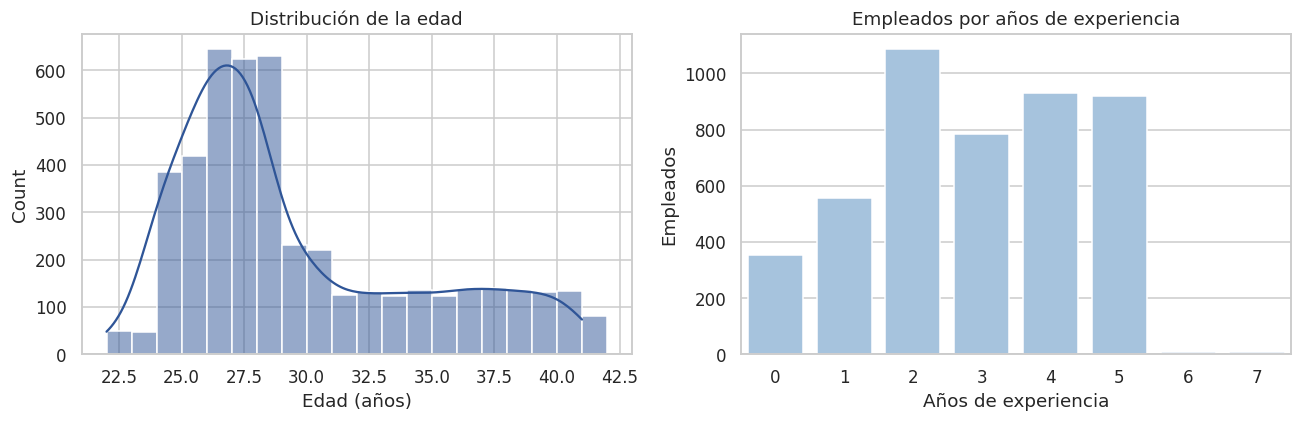

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["edad"], bins=range(22, 43), kde=True, ax=axes[0], color="#2F5597")
axes[0].set_title("Distribución de la edad")
axes[0].set_xlabel("Edad (años)")
sns.countplot(data=df, x="experiencia_anios", ax=axes[1], color="#9DC3E6")
axes[1].set_title("Empleados por años de experiencia")
axes[1].set_xlabel("Años de experiencia")
axes[1].set_ylabel("Empleados")
plt.tight_layout()
plt.show()

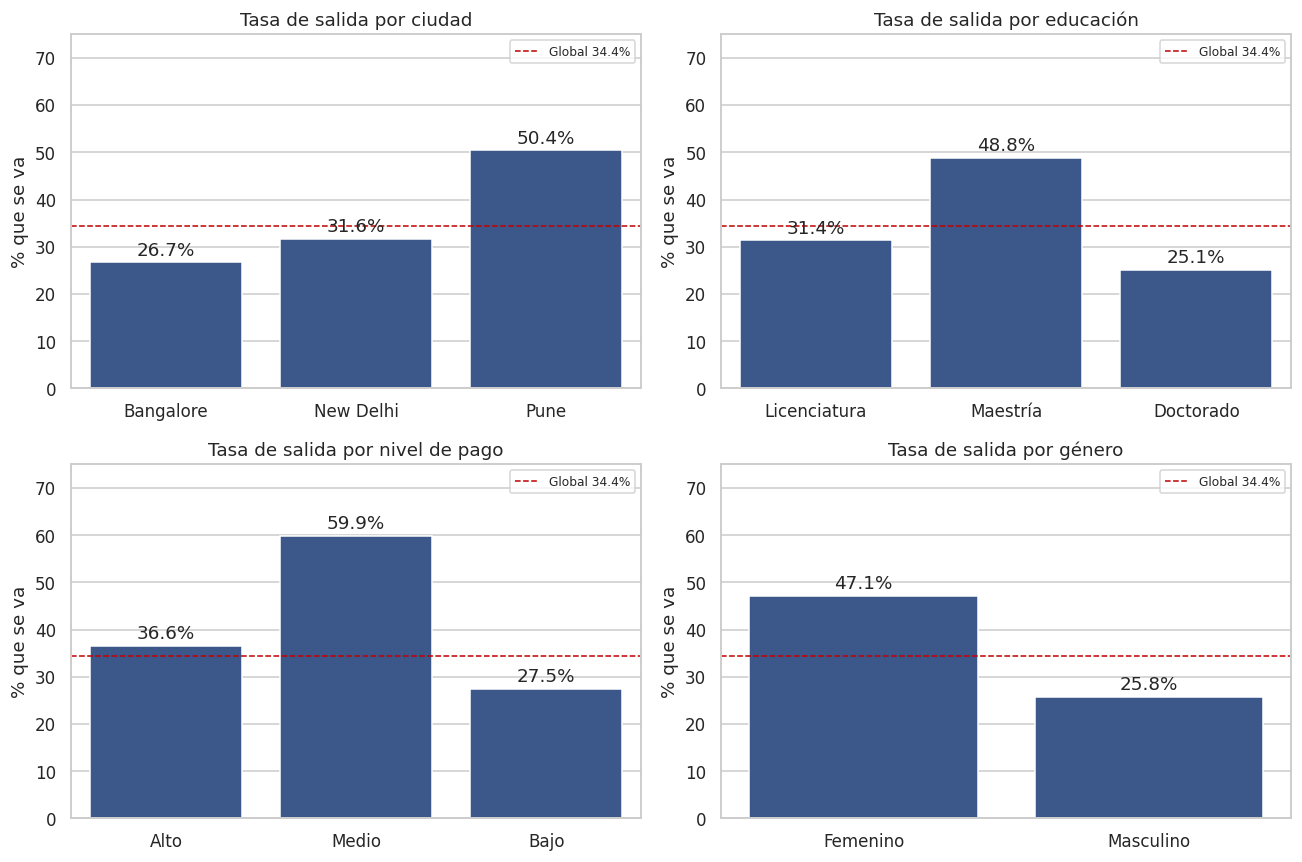

In [9]:
tasa_global = df["salida_2_anios"].mean() * 100


def barra_tasa(ax, col, orden=None, titulo=None):
    t = df.groupby(col)["salida_2_anios"].mean() * 100
    if orden:
        t = t.reindex(orden)
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax, color="#2F5597")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.axhline(tasa_global, color="#C00000", ls="--", lw=1, label=f"Global {tasa_global:.1f}%")
    ax.set_title(titulo or f"Tasa de salida por {col}")
    ax.set_xlabel("")
    ax.set_ylabel("% que se va")
    ax.set_ylim(0, 75)
    ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
barra_tasa(axes[0, 0], "ciudad", titulo="Tasa de salida por ciudad")
barra_tasa(axes[0, 1], "educacion", ["Licenciatura", "Maestría", "Doctorado"], "Tasa de salida por educación")
barra_tasa(axes[1, 0], "nivel_pago_texto", ["Alto", "Medio", "Bajo"], "Tasa de salida por nivel de pago")
barra_tasa(axes[1, 1], "genero", titulo="Tasa de salida por género")
plt.tight_layout()
plt.show()

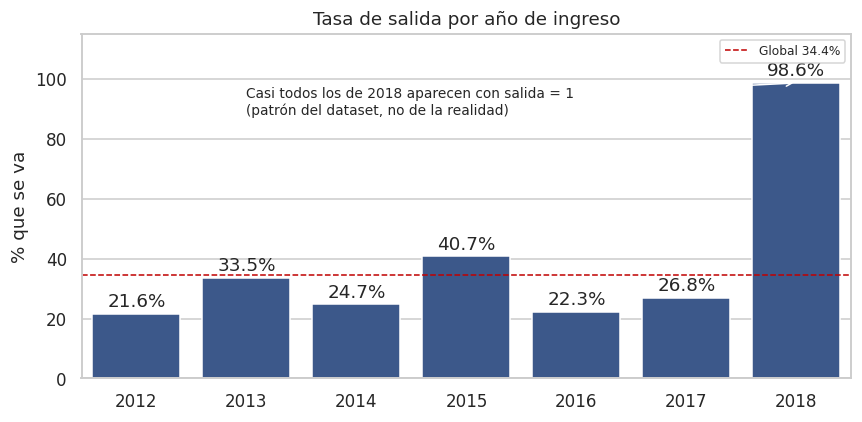

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
barra_tasa(ax, "anio_ingreso", titulo="Tasa de salida por año de ingreso")
ax.set_ylim(0, 115)
ax.annotate("Casi todos los de 2018 aparecen con salida = 1\n(patrón del dataset, no de la realidad)",
            xy=(6, 98.6), xytext=(1.0, 88), arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.tight_layout()
plt.show()

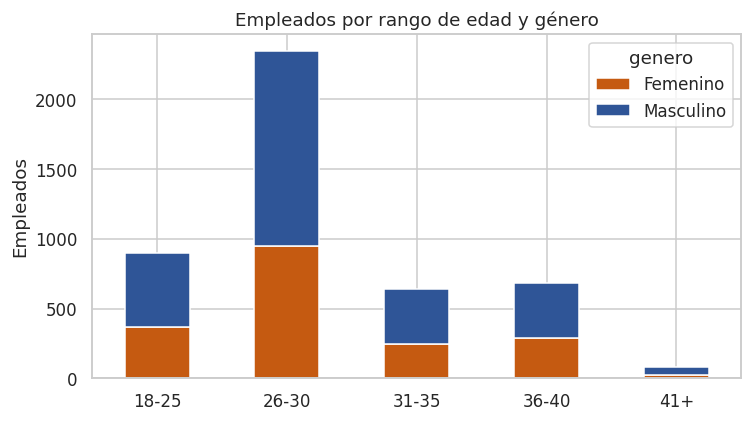

In [11]:
tabla = pd.crosstab(df["rango_edad"], df["genero"])
ax = tabla.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#C55A11", "#2F5597"], rot=0)
ax.set_title("Empleados por rango de edad y género")
ax.set_xlabel("")
ax.set_ylabel("Empleados")
plt.tight_layout()
plt.show()

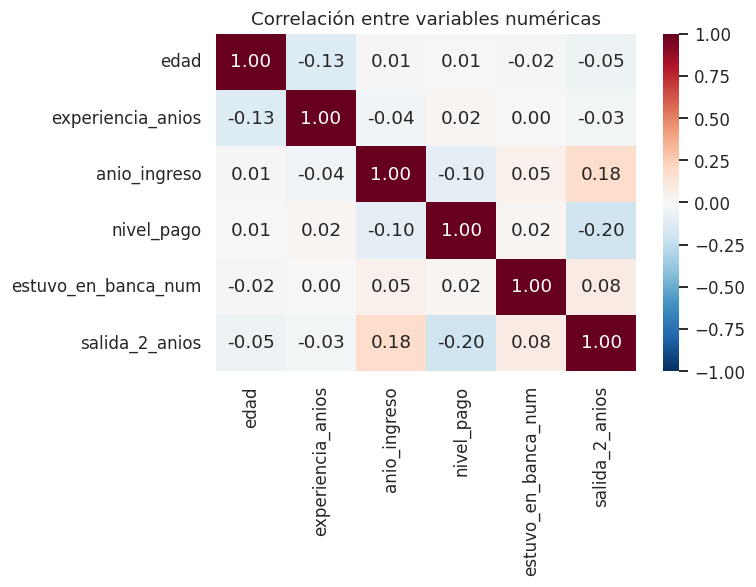

In [12]:
cols = ["edad", "experiencia_anios", "anio_ingreso", "nivel_pago", "estuvo_en_banca_num", "salida_2_anios"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

**Interpretación**
- La **tasa de salida global es 34.4 %**. Por ciudad, Pune destaca con 50.4 %, frente a 31.6 % en New Delhi y 26.7 % en Bangalore.
- Por educación, maestría tiene 48.8 %, licenciatura 31.4 % y doctorado 25.1 % (solo 179 personas, así que ese dato es menos estable).
- Por nivel de pago, el nivel medio tiene la tasa más alta (59.9 %), pero con 918 personas; el nivel bajo, que agrupa a 3,492, tiene 27.5 %.
- Por género, 47.1 % en mujeres y 25.8 % en hombres. Es una diferencia grande dentro de este dataset; no demuestra una causa, y puede mezclarse con la ciudad, la educación o el año de ingreso.
- Quienes estuvieron en banca tienen 45.4 % frente a 33.1 % de quienes no.
- Las **correlaciones con la salida son débiles** (la mayor, con `nivel_pago`, es −0.20). La asociación con `anio_ingreso` (0.18) se debe casi por completo al 98.6 % de salida en 2018.

## 6. ¿Importan las filas repetidas?

Se comparan las tasas de salida con todas las filas y sin las repetidas.

In [13]:
def tasas(d):
    out = {"Global": d["salida_2_anios"].mean()}
    for col in ["ciudad", "educacion", "genero"]:
        out.update(d.groupby(col)["salida_2_anios"].mean().to_dict())
    return pd.Series(out)


comp = pd.DataFrame({"todas (%)": tasas(df) * 100, "sin repetidas (%)": tasas(sin_rep) * 100})
comp["diferencia (puntos)"] = comp["sin repetidas (%)"] - comp["todas (%)"]
comp.round(1)

,todas (%),sin repetidas (%),diferencia (puntos)
Global,34.4,39.4,5.0
Bangalore,26.7,35.0,8.3
New Delhi,31.6,34.1,2.5
Pune,50.4,50.9,0.5
Doctorado,25.1,25.6,0.5
Licenciatura,31.4,37.5,6.1
Maestría,48.8,48.5,-0.3
Femenino,47.1,49.7,2.6
Masculino,25.8,31.0,5.2


La tasa global sube de 34.4 % a 39.4 % al quitar las repetidas, así que **la decisión sí mueve los resultados**. Pune sigue siendo la ciudad con mayor tasa (50.9 %) y maestría sigue por encima de doctorado, pero Bangalore pasa de 26.7 % a 35.0 % y supera a New Delhi (34.1 %), y la diferencia entre mujeres y hombres se reduce (de 21 a 19 puntos: 49.7 % frente a 31.0 %). Por eso hay que declarar en el README qué versión usa cada dashboard (por defecto, todas las filas) y mencionar esta sensibilidad en la defensa.

## 7. Conclusiones

1. El dataset cumple el volumen (41,877 datos), no tiene nulos y no trae errores de rango; el trabajo de limpieza consistió en estandarizar, traducir, identificar filas repetidas y crear variables derivadas.
2. La plantilla es joven (media de 29.4 años, mediana de 28) y con poca antigüedad (media de 2.9 años).
3. La salida a 2 años es de 34.4 %, con diferencias marcadas por ciudad, educación, nivel de pago y género. Las correlaciones numéricas son débiles.
4. Limitaciones: no hay ID, los datos parecen sintéticos o pre-procesados (patrón de 2018) y las filas repetidas cambian la tasa global en 5 puntos.
5. Para el dashboard: tasa de salida por ciudad, educación y nivel de pago; total de empleados por año de ingreso; y composición por rango de edad y género.

## 8. Exportación

Se guarda el dataset limpio que consumirá Power BI.

In [14]:
CLEAN.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN, index=False, encoding="utf-8-sig")
print("Guardado:", CLEAN, "| filas y columnas:", df.shape, "| datos:", df.size)

Guardado: ../data/clean/empleados_limpio.csv | filas y columnas: (4653, 18) | datos: 83754
